# How good is the GPU model?

**The goal:** a model that's portable and easy to calibrate from the junction sensor and power alone, and that then predicts the junction from power alone.

**The model is three layers between the chip and the water.** Think of three buckets connected by pipes, with heat poured into the first. **C** is how wide a bucket is (wide takes longer to fill) and **R** is how narrow the pipe out of it is (narrow makes the level stand higher). The level in the first bucket, added to the coolant temperature, is the junction temperature.

```
power --> [ die ] --R1--> [ package ] --R2--> [ cold plate ] --R3--> coolant
            C1               C2                  C3
```

**Using it takes two commands:**

```
./fit_gpu gpu_fit.h gpu0.txt gpu1.txt ...        # calibrate: each line is power_W timestamp_s junction_C
./predict_gpu 0 power.txt > predicted.csv        # predict: only power and time are used
```

**The questions, and short answers:**

| Question | Answer |
|---|---|
| Does it predict data it never saw? | Yes: 0.82 °C against raw readings and 0.36 °C on half-second averages, across 20 GPUs (Step 1) |
| Is three layers the right number? | Yes: fewer is clearly worse, and more adds nothing (Step 2) |
| Does it carry over to a different job? | About 1 °C, even on a different physical GPU, when calibrated on rocHPL (Step 3) |
| Is it tied to Frontier's wattage? | No (Step 4) |
| Can it learn Frontier's cooling from junction and power? | In a test built on the real inlet, yes: peak error falls from about 5 °C to under 0.5 °C (Step 5) |

**About the data:** these are 5 Score-P traces from 5 different Frontier nodes, so 20 physical GPUs. There are 3 rocHPL runs and 2 HPG-MxP runs, a very different benchmark. All of them are single-node jobs.

In [1]:
import io, shutil, subprocess, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, lsq_linear
from scipy.signal import lfilter

HERE = Path('.').resolve()
GPUS = [0, 1, 2, 3]
JOBS = {'rocHPL': HERE / 'samples', 'rocHPL, captured params': HERE / 'samples' / 'hpl-captured-params', 'rocHPL, HIP': HERE / 'samples' / 'hpl-captured-params-HIP',
        'HPG-MxP, low power': HERE / 'samples' / 'hpgmxp', 'HPG-MxP': HERE / 'samples' / 'hpg-mxp'}
SENSOR, MODEL, OTHER = '#8a8a86', '#2a78d6', '#eb6834'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.5})
pd.set_option('display.width', 200, 'display.max_columns', 30)

def run(command, cwd=HERE):
    return subprocess.run([str(c) for c in command], cwd=cwd, capture_output=True, text=True, check=True).stdout

def load(folder, gpu):
    return pd.read_csv(folder / f'gpu{gpu}.txt', sep=' ', names=['power_W', 'time_s', 'junction_C'])

SAMPLES = {(job, g): load(folder, g) for job, folder in JOBS.items() for g in GPUS}

def calibrate(folder, tables):
    '''Run fit_gpu on {gpu: samples}, and build predict_gpu with its numbers. Returns what fit_gpu printed.'''
    folder = Path(folder)
    shutil.copy(HERE / 'predict_gpu.c', folder); shutil.copy(HERE / 'gpu_model.h', folder)
    for g, table in tables.items():
        table[['power_W', 'time_s', 'junction_C']].to_csv(folder / f'in{g}.txt', sep=' ', header=False, index=False, na_rep='nan')
    log = run([HERE / 'fit_gpu', 'gpu_fit.h'] + [f'in{g}.txt' for g in tables], cwd=folder)
    run(['cc', '-O2', 'predict_gpu.c', '-lm', '-o', 'predict_gpu'], cwd=folder)
    return log

def predict(folder, gpu, samples, *options):
    '''Junction from power alone: predict_gpu never sees the junction column unless told to use it.'''
    path = Path(folder) / 'all.txt'
    samples[['power_W', 'time_s', 'junction_C']].to_csv(path, sep=' ', header=False, index=False, na_rep='nan')
    return pd.read_csv(io.StringIO(run(['./predict_gpu', gpu, 'all.txt', *options], cwd=folder)))

def half_second_means(time_s, values):
    bins = np.floor(np.asarray(time_s) / 0.5).astype(int)
    return np.bincount(bins, values)[np.unique(bins)] / np.bincount(bins)[np.unique(bins)]

def score(output, samples, start=0.0):
    '''Compare with the sensor: every reading, and on half-second averages, which removes the sensor's flicker.'''
    readings = samples[samples.junction_C.notna() & (samples.time_s >= start)]
    t, sensor = readings.time_s.to_numpy(), readings.junction_C.to_numpy()
    model = np.interp(t, output.time_s, output.junction_C)
    a, b = half_second_means(t, model), half_second_means(t, sensor)
    return dict(raw=np.sqrt(np.mean((model - sensor) ** 2)), smooth=np.sqrt(np.mean((a - b) ** 2)), worst=np.abs(a - b).max(),
                flicker=np.sqrt(np.mean((sensor - b[np.unique(np.floor(t / 0.5).astype(int), return_inverse=True)[1]]) ** 2)))

## Step 1: Predict what it never saw

For each of the 20 GPUs, `fit_gpu` gets only the first 60% of its run. `predict_gpu` then predicts the whole run from power, and the score comes from the last 40%.

**Two scores, because the sensor flickers.** It reads in 1 °C steps and jumps around, even when the temperature is hardly changing. So the error against raw readings can't get close to zero, no matter how good the model is. The second score compares half-second averages, which removes most of that flicker and shows what the model really gets wrong.

All 20 GPUs, on the 40% of each run the fit never saw: 0.82 °C against raw readings, 0.36 °C on 0.5 s averages; worst single GPU 0.75 °C; worst 0.5 s anywhere 1.70 °C


,job,length,junction swing,error vs raw sensor,error vs 0.5 s averages,worst GPU,worst 0.5 s anywhere,sensor flicker within 0.5 s
0,rocHPL,82 s,27 °C,0.79 °C,0.31 °C,0.39 °C,1.39 °C,0.99 °C
1,"rocHPL, captured params",102 s,25 °C,0.88 °C,0.25 °C,0.29 °C,1.33 °C,1.47 °C
2,"rocHPL, HIP",103 s,26 °C,0.88 °C,0.30 °C,0.36 °C,1.70 °C,1.46 °C
3,"HPG-MxP, low power",54 s,8 °C,0.67 °C,0.36 °C,0.61 °C,0.81 °C,0.59 °C
4,HPG-MxP,58 s,15 °C,0.87 °C,0.60 °C,0.75 °C,1.27 °C,0.86 °C


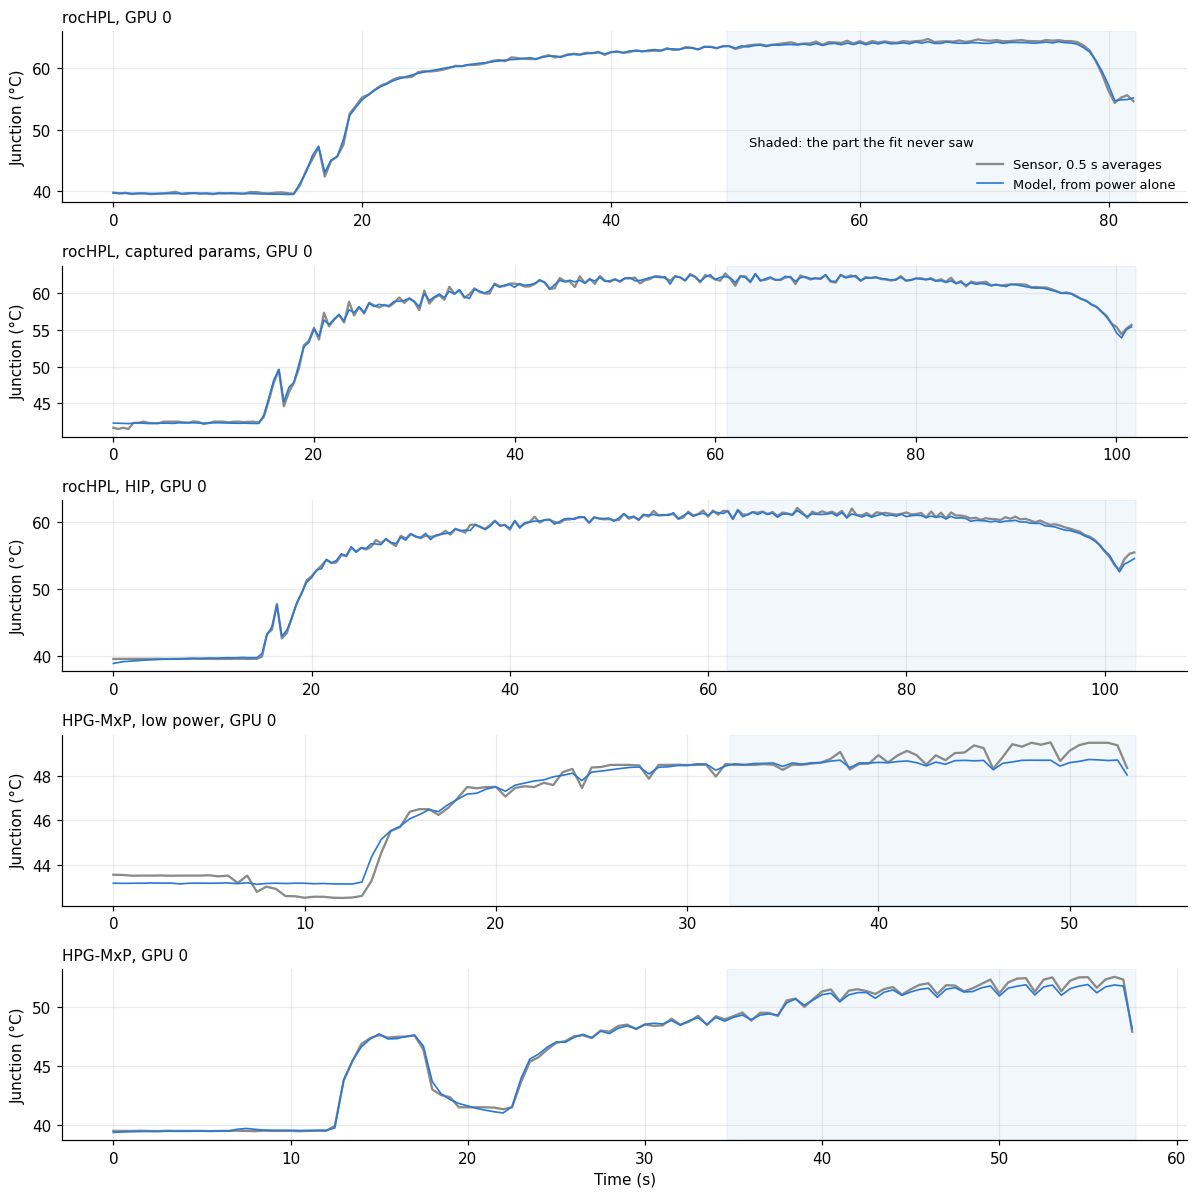

In [2]:
FIT_SHARE = 0.6
rows, curves = [], {}
for job in JOBS:
    with tempfile.TemporaryDirectory() as folder:
        ends = {g: SAMPLES[job, g].time_s.max() * FIT_SHARE for g in GPUS}
        calibrate(folder, {g: SAMPLES[job, g][SAMPLES[job, g].time_s < ends[g]] for g in GPUS})
        scores = []
        for g in GPUS:
            output = predict(folder, g, SAMPLES[job, g])
            scores.append(score(output, SAMPLES[job, g], ends[g]))
            if g == 0: curves[job] = (output, ends[g])
    s = pd.DataFrame(scores)
    rows.append({'job': job, 'length': f'{SAMPLES[job, 0].time_s.max():.0f} s', 'junction swing': f"{SAMPLES[job, 0].junction_C.max() - SAMPLES[job, 0].junction_C.min():.0f} °C",
                 'error vs raw sensor': f'{s.raw.mean():.2f} °C', 'error vs 0.5 s averages': f'{s.smooth.mean():.2f} °C', 'worst GPU': f'{s.smooth.max():.2f} °C', 'worst 0.5 s anywhere': f'{s.worst.max():.2f} °C', 'sensor flicker within 0.5 s': f'{s.flicker.mean():.2f} °C'})
    rows[-1]['_raw'], rows[-1]['_smooth'], rows[-1]['_worst'] = s.raw.tolist(), s.smooth.tolist(), s.worst.max()
table = pd.DataFrame(rows)
print(f"All 20 GPUs, on the 40% of each run the fit never saw: {np.mean(sum(table._raw, [])):.2f} °C against raw readings, {np.mean(sum(table._smooth, [])):.2f} °C on 0.5 s averages; worst single GPU {np.max(sum(table._smooth, [])):.2f} °C; worst 0.5 s anywhere {table._worst.max():.2f} °C")
display(table.drop(columns=['_raw', '_smooth', '_worst']))

fig, axes = plt.subplots(5, 1, figsize=(11, 11))
for ax, job in zip(axes, JOBS):
    output, end = curves[job]
    readings = SAMPLES[job, 0][SAMPLES[job, 0].junction_C.notna()]
    bins = np.floor(readings.time_s.to_numpy() / 0.5).astype(int)
    ax.plot(np.unique(bins) * 0.5, half_second_means(readings.time_s, readings.junction_C), color=SENSOR, label='Sensor, 0.5 s averages')
    ax.plot(np.unique(bins) * 0.5, half_second_means(readings.time_s, np.interp(readings.time_s, output.time_s, output.junction_C)), color=MODEL, linewidth=1.1, label='Model, from power alone')
    ax.axvspan(end, readings.time_s.max(), color='#2a78d6', alpha=0.06)
    ax.set_ylabel('Junction (°C)'); ax.set_title(f'{job}, GPU 0', loc='left', fontsize=10)
axes[0].legend(frameon=False, fontsize=8.5, loc='lower right')
axes[0].annotate('Shaded: the part the fit never saw', (0.61, 0.33), xycoords='axes fraction', fontsize=8.5)
axes[-1].set_xlabel('Time (s)')
plt.tight_layout(); plt.savefig('validation_all_jobs.png', dpi=130, bbox_inches='tight'); plt.show()

**How to read this figure.** Each panel is GPU 0 of one job, with no picking of a favourite. Gray is the sensor and blue is the model. In the shaded part, the fit had seen nothing, and only power goes in.

**What it shows:**

* **On rocHPL the lines lie on top of each other,** including the fast dips and the final drop. Error is 0.25–0.31 °C.
* **The error against raw readings (0.82 °C) is about the size of the sensor's own flicker** (0.6–1.5 °C within half a second).
* **HPG-MxP is harder,** with errors of 0.36–0.60 °C. Its runs are short, so the fit has only seen about 20 s of load before being scored, and the slow layer isn't pinned down. You can see the model drifting up to about 0.8 °C low by the end.

**One thing to notice:** the worst half-second anywhere across all 20 GPUs is 1.70 °C.

## Step 2: Is three layers the right number?

More layers can always fit better, so what counts is the error on unseen data. This runs the same test with 1 to 4 layers.

In [3]:
# A small separate solver, only for this comparison, since the C model has exactly 3 layers.
# Any stack of layers responds like a sum of first-order lags, one per layer, so the layer count is the number of lags.
STEP = 0.005

def on_grid(samples):
    power = samples[samples.junction_C.isna()]
    t, p = power.time_s.to_numpy(), power.power_W.to_numpy()
    energy = np.r_[0, np.cumsum(p[:-1] * np.diff(t))]
    grid = np.arange(t[0], t[-1] - STEP, STEP)
    return grid, np.diff(np.interp(np.r_[grid, grid[-1] + STEP], t, energy)) / STEP

def lags(p, times, where):
    filtered = []
    for tau in times:
        keep = np.exp(-STEP / tau)
        out, _ = lfilter([1 - keep], [1, -keep], p, zi=[keep * p[:200].mean()])
        filtered.append(out[where] / 100)
    return np.column_stack([np.ones(len(where))] + filtered)

def solve_lift(X, y):
    return lsq_linear(X, y, bounds=([-np.inf] + [0] * (X.shape[1] - 1), np.inf)).x

STARTS = {1: [10.0], 2: [0.1, 12.0], 3: [0.03, 1.5, 16.0], 4: [0.03, 0.4, 3.0, 20.0]}
results = {n: [] for n in STARTS}
for (job, g), samples in SAMPLES.items():
    grid, p = on_grid(samples)
    readings = samples[samples.junction_C.notna()]
    t, y = readings.time_s.to_numpy(), readings.junction_C.to_numpy()
    where = np.minimum(np.searchsorted(grid, t), len(grid) - 1)
    seen = t < t[-1] * FIT_SHARE
    for n, start in STARTS.items():
        residual = lambda logs: (lambda X: X @ solve_lift(X, y[seen]) - y[seen])(lags(p, np.exp(logs), where[seen]))
        best = np.exp(least_squares(residual, np.log(start), diff_step=0.02, max_nfev=40).x)
        lift = solve_lift(lags(p, best, where[seen]), y[seen])
        model = lags(p, best, where) @ lift
        results[n].append((np.sqrt(np.mean((model - y)[~seen] ** 2)), np.sqrt(np.mean((half_second_means(t[~seen], model[~seen]) - half_second_means(t[~seen], y[~seen])) ** 2))))
pd.DataFrame([{'layers': n, 'error vs raw sensor': f'{np.mean(results[n], 0)[0]:.2f} °C', 'error vs 0.5 s averages': f'{np.mean(results[n], 0)[1]:.2f} °C', 'worst GPU': f'{np.max(results[n], 0)[1]:.2f} °C'} for n in STARTS])

/Users/hom/miniconda3/envs/ampere_dev/lib/python3.11/site-packages/scipy/optimize/_lsq/trf_linear.py:116: RuntimeWarning: invalid value encountered in multiply
  r_h = p_h + r_h * r_stride


,layers,error vs raw sensor,error vs 0.5 s averages,worst GPU
0,1,1.91 °C,1.58 °C,2.39 °C
1,2,1.15 °C,0.85 °C,1.45 °C
2,3,0.83 °C,0.35 °C,0.73 °C
3,4,0.84 °C,0.37 °C,0.76 °C


**What this shows.** Going from 1 to 2 to 3 layers cuts the error sharply. A 4th makes it no better. So three is the right size, and this data doesn't need anything more complicated. I also tried a telemetry delay, a power-dependent gain and a slow extra term, and none of them helped.

## Step 3: A different job, on a different GPU

Everything so far calibrated and tested on the same run. What you really want is to calibrate once, then predict *other* jobs.

**This data can't test that directly,** because no node appears in two traces. The closest available test is harder: calibrate on one job and predict a different job **on a different physical GPU in the same slot**. That's a fair stand-in only if GPUs in the same slot really are alike, which the figure below checks. Because it's a different node with different coolant, the coolant is set once from the idle stretch at the start of the run. After that, only power goes in.

Each row of the table is the job calibrated on, and each column is the job predicted. The diagonal is the same run the fit was calibrated on.

,rocHPL,"rocHPL, captured params","rocHPL, HIP","HPG-MxP, low power",HPG-MxP
rocHPL,0.33 °C,0.44 °C,0.99 °C,1.58 °C,0.75 °C
"rocHPL, captured params",0.55 °C,0.25 °C,0.82 °C,1.56 °C,0.69 °C
"rocHPL, HIP",1.01 °C,0.75 °C,0.32 °C,1.54 °C,0.68 °C
"HPG-MxP, low power",4.70 °C,3.98 °C,4.14 °C,0.26 °C,1.53 °C
HPG-MxP,1.23 °C,1.17 °C,1.26 °C,1.19 °C,0.22 °C


Calibrated on rocHPL, predicting a different job on a different GPU: 0.95 °C on average, from 0.44 to 1.58 °C


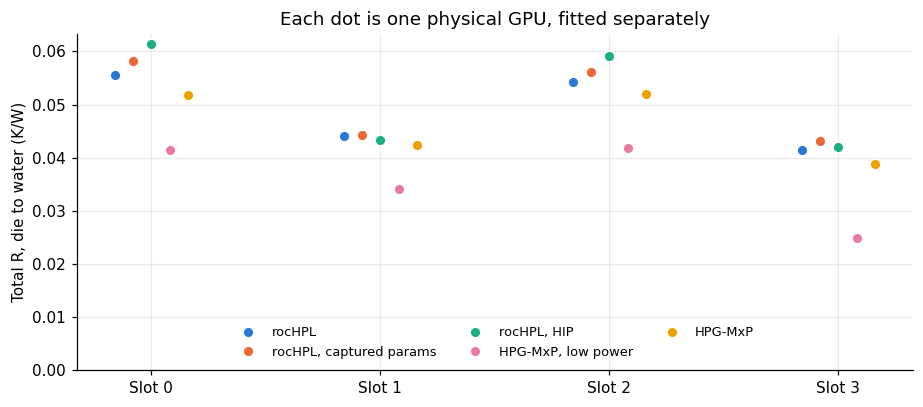

In [4]:
JOB_NAMES = list(JOBS)
matrix = pd.DataFrame(index=JOB_NAMES, columns=JOB_NAMES, dtype=float)
total_R = {}
for train in JOB_NAMES:
    with tempfile.TemporaryDirectory() as folder:
        calibrate(folder, {g: SAMPLES[train, g] for g in GPUS})
        fits = [line for line in (Path(folder) / 'gpu_fit.h').read_text().splitlines() if line.startswith('    {{')]
        total_R[train] = [sum(float(x) for x in line.split('{{')[1].split('}')[0].split(',')) for line in fits]
        for test in JOB_NAMES:
            errors = []
            for g in GPUS:
                output = predict(folder, g, SAMPLES[test, g])
                # Different node, so different coolant: set it once, from the idle stretch at the start of the run
                idle = SAMPLES[test, g][SAMPLES[test, g].junction_C.notna() & (SAMPLES[test, g].time_s < 10)]
                shift = np.mean(idle.junction_C - np.interp(idle.time_s, output.time_s, output.junction_C))
                output.junction_C += shift
                errors.append(score(output, SAMPLES[test, g])['smooth'])
            matrix.loc[train, test] = np.mean(errors)
display(matrix.style.format('{:.2f} °C').background_gradient(cmap='Blues', vmin=0, vmax=5))
hpl = JOB_NAMES[:3]
others = [matrix.loc[a, b] for a in hpl for b in JOB_NAMES if a != b]
print(f"Calibrated on rocHPL, predicting a different job on a different GPU: {np.mean(others):.2f} °C on average, from {np.min(others):.2f} to {np.max(others):.2f} °C")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for index, job in enumerate(JOB_NAMES):
    ax.plot(np.array(GPUS) + (index - 2) * 0.08, total_R[job], 'o', markersize=7, label=job, color=['#2a78d6', '#eb6834', '#1baf7a', '#e87ba4', '#eda100'][index], markeredgecolor='white', markeredgewidth=1)
ax.set_xticks(GPUS); ax.set_xticklabels([f'Slot {g}' for g in GPUS]); ax.set_ylabel('Total R, die to water (K/W)'); ax.set_ylim(bottom=0)
ax.set_title('Each dot is one physical GPU, fitted separately'); ax.legend(frameon=False, fontsize=8.5, ncol=3, loc='lower center')
plt.tight_layout(); plt.savefig('total_R_by_slot.png', dpi=130, bbox_inches='tight'); plt.show()

**What the table shows.**

* **Calibrated on rocHPL, it predicts other jobs on other GPUs to 0.95 °C on average** (0.44–1.58 °C). A calibration on the same GPU should do better than this, though there's no data here to prove it.
* **Don't calibrate on a gentle job.** The low-power HPG-MxP row is 3.7–4.7 °C off on rocHPL, because a junction swing of 8 °C with a 1 °C sensor can't pin down the layers. `fit_gpu` now warns about this: it asks for a swing of at least 15 °C.
* **The low-power HPG-MxP column is off by about 1.5 °C from every rocHPL calibration.** This one looks physical, and I couldn't fix it.

**How to read the figure.** Each dot is one physical GPU's total R. Same-slot GPUs on different nodes land close together, with slots 0 and 2 near 0.056 K/W and slots 1 and 3 near 0.044 K/W. This says the fit is measuring real hardware, probably how the water is plumbed through each node.

The pink dots (low-power HPG-MxP) sit about 25% lower. That job gets less junction rise per watt than the other runs do. My best guess is that at low power, more of the counted power goes to memory, not the die, but this data can't confirm that. If so, it's a limit of using a single power counter, and it would affect any model that uses only this input.

## Step 4: Is it tied to Frontier's wattage?

Another GPU may draw much less or much more. So this takes one real trace, scales its power, and calibrates again. A portable calibrator should get the same quality, with R scaled to match.

In [5]:
rows = []
with tempfile.TemporaryDirectory() as folder:
    for k in (0.1, 0.25, 1.0, 3.0):
        scaled = SAMPLES['rocHPL, captured params', 0].copy()
        scaled['power_W'] *= k
        log = calibrate(folder, {0: scaled}).splitlines()
        rows.append({'power scaled by': k, 'power range': log[0].split('power ')[1].split(';')[0], 'total R (K/W)': log[0].split('= ')[1].split(' K/W')[0], 'error': log[1].split('error ')[1].split(' over')[0]})
pd.DataFrame(rows)

,power scaled by,power range,total R (K/W),error
0,0.10,9 to 58 W,0.5819,0.93 °C
1,0.25,23 to 144 W,0.2327,0.93 °C
2,1.00,94 to 577 W,0.0582,0.93 °C
3,3.00,282 to 1730 W,0.0194,0.93 °C


**What this shows.** The error is identical, and R scales exactly in inverse proportion, from 58 W to 1730 W. That's because the first guess now comes from how far the junction moved per watt in that run, with no Frontier numbers in it.

**Be careful:** this confirms the calibrator isn't tied to one wattage. It isn't a test on real hardware of another type, like Lux.

## Step 5: Frontier's complex cooling, from junction and power

When a whole cooling group runs a job, the water warms by several degrees, and then the CDU catches up and brings it back. Each GPU's junction rides on top of that. So a model that assumes steady water will be wrong by that much.

**The model handles this with 3 more numbers:** how far the coolant moves per watt, how fast it rises, and how fast it settles back. Earlier versions fitted those to a measured inlet temperature. Now `fit_gpu` finds them **from junction and power alone**. If a run lasts at least 5 minutes, it tries them, and it keeps them only if they predict the held-back part of the run better.

**The test.** There are no real junction readings for a group-wide run, so this builds them from the parts that are real:

```
junction = the real measured inlet from the 3-cabinet run + 4 °C + the layers' lift from the real power trace
```

The inlet and power are real. The 4 °C step and the layers' lift come from assumptions and the model, with a 1 °C sensor and noise added. `fit_gpu` sees only power and junction, so it's never given the inlet.

The real inlet moved from 26.8 to 33.2 °C over 1622 s


GPU 0: R 0.0160 + 0.0265 + 0.0169 = 0.0594 K/W; C 2.08, 83.6, 2239 J/K; coolant 31.1 °C; power 90 to 556 W; margin 1.0 °C
    error 0.43 °C over 12001 readings; on the last 30% when fitted only on the rest: 0.46 °C
    water moved: gain 0.0466 °C/W, rise 46 s, settle 46 s (held-back error 1.74 °C without it)
GPU 1: R 0.0171 + 0.0196 + 0.0113 = 0.0479 K/W; C 1.94, 77.9, 3995 J/K; coolant 31.1 °C; power 89 to 551 W; margin 1.0 °C
    error 0.43 °C over 12001 readings; on the last 30% when fitted only on the rest: 0.43 °C
    water moved: gain 0.0492 °C/W, rise 44 s, settle 44 s (held-back error 1.77 °C without it)
GPU 2: R 0.0128 + 0.0279 + 0.0175 = 0.0581 K/W; C 1.59, 58.8, 1894 J/K; coolant 31.1 °C; power 89 to 558 W; margin 1.0 °C
    error 0.44 °C over 12001 readings; on the last 30% when fitted only on the rest: 0.48 °C
    water moved: gain 0.0427 °C/W, rise 50 s, settle 50 s (held-back error 1.77 °C without it)
GPU 3: R 0.0155 + 0.0199 + 0.0100 = 0.0454 K/W; C 2.28, 67.9, 4835 J/K

,after calibration: water switched off,after calibration: with learned water,"whole run, after 100 s: water switched off","whole run, after 100 s: with learned water"
calibrated on the first (s),,,,
400,0.42,0.25,1.26,0.23
600,0.53,0.18,1.24,0.16
1000,0.69,0.23,1.24,0.16
1400,0.90,0.42,1.22,0.18


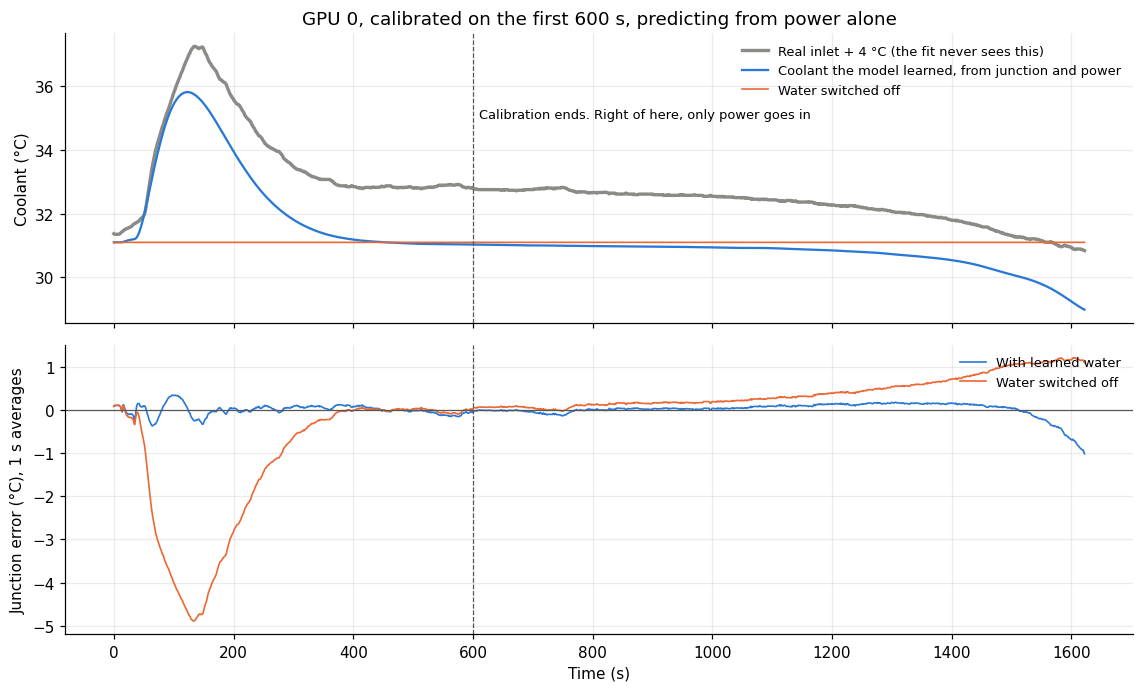

In [6]:
telemetry = pd.read_csv(HERE.parent / '3Cab_POW.txt', sep=r'\s+', skiprows=11)
start = pd.to_datetime(telemetry.TS.iloc[0])
t_telemetry = (pd.to_datetime(telemetry.TS) - start).dt.total_seconds().to_numpy()
recon = pd.read_csv(HERE.parent / 'cabinet_power_recon_gpu_energy_1ms.csv')
offset = (pd.to_datetime(recon.utc.iloc[0], utc=True) - start).total_seconds() - recon.t_since_job_start_s.iloc[0]
t = recon.t_since_job_start_s.to_numpy() + offset
absolute_t, t = t, t - t[0]

RISE_TO_GPU = 4.0     # an assumed step from the rack inlet to this GPU's plate
rng = np.random.default_rng(3)
GROUP = {}
for g in GPUS:
    p = recon[f'C1_gpu{g + 1}_energy_W'].to_numpy() / 128
    # The layers' lift, from the real GPU numbers fitted on rocHPL, with the water off
    layers = pd.read_csv(io.StringIO(subprocess.run(['./predict_gpu', str(g), '/dev/stdin'], input='\n'.join(f'{a:.3f} {b:.3f}' for a, b in zip(p, t)), capture_output=True, text=True, check=True).stdout), usecols=['junction_C', 'coolant_C'])
    coolant = np.interp(absolute_t, t_telemetry, telemetry.LIT_C1.to_numpy(float)) + RISE_TO_GPU
    junction = coolant + (layers.junction_C - layers.coolant_C).to_numpy()
    readings = np.full(len(t), np.nan)
    every = np.arange(0, len(t), 50)                                # a reading every 50 ms
    readings[every] = np.round(junction[every] + rng.normal(0, 0.3, len(every)))      # in 1 °C steps, with some noise
    GROUP[g] = dict(table=pd.DataFrame({'power_W': p, 'time_s': t, 'junction_C': readings}), truth=junction, coolant=coolant)
print(f"The real inlet moved from {GROUP[0]['coolant'].min() - RISE_TO_GPU:.1f} to {GROUP[0]['coolant'].max() - RISE_TO_GPU:.1f} °C over {t[-1]:.0f} s")

def second_means(values):
    seconds = (t // 1).astype(int)
    return np.bincount(seconds, values) / np.bincount(seconds)

rows, kept = [], {}
for end_s in (400, 600, 1000, 1400):
    with tempfile.TemporaryDirectory() as folder:
        log = calibrate(folder, {g: GROUP[g]['table'][t < end_s] for g in GPUS})
        if end_s == 600: print(log)
        for g in GPUS:
            for label, options in (('water', ['group']), ('steady', [])):
                output = predict(folder, g, GROUP[g]['table'][['power_W', 'time_s', 'junction_C']], *options)
                error = second_means(output.junction_C.to_numpy() - GROUP[g]['truth'])
                rows.append(dict(end_s=end_s, gpu=g, label=label, unseen=np.sqrt(np.mean(error[end_s:] ** 2)), whole=np.sqrt(np.mean(error[100:] ** 2)), worst=np.abs(error[end_s:]).max()))
                if end_s == 600 and g == 0: kept[label] = output
results = pd.DataFrame(rows)
summary = results.pivot_table(index='end_s', columns='label', values=['unseen', 'whole']).round(2)
summary.columns = [f"{'after calibration' if a == 'unseen' else 'whole run, after 100 s'}: {'with learned water' if b == 'water' else 'water switched off'}" for a, b in summary.columns]
summary.index.name = 'calibrated on the first (s)'
display(summary)

fig, axes = plt.subplots(2, 1, figsize=(10.5, 6.4), sharex=True)
seconds = np.arange(int(t[-1]) + 1)
axes[0].plot(seconds, second_means(GROUP[0]['coolant']), color=SENSOR, linewidth=2.2, label='Real inlet + 4 °C (the fit never sees this)')
axes[0].plot(seconds, second_means(kept['water'].coolant_C.to_numpy()), color=MODEL, label='Coolant the model learned, from junction and power')
axes[0].plot(seconds, second_means(kept['steady'].coolant_C.to_numpy()), color=OTHER, linewidth=1.1, label='Water switched off')
axes[0].set_ylabel('Coolant (°C)'); axes[0].legend(frameon=False, fontsize=8.5, loc='upper right')
axes[0].set_title('GPU 0, calibrated on the first 600 s, predicting from power alone')
for label, color, name in (('water', MODEL, 'With learned water'), ('steady', OTHER, 'Water switched off')):
    axes[1].plot(seconds, second_means(kept[label].junction_C.to_numpy() - GROUP[0]['truth']), color=color, linewidth=1.1, label=name)
axes[1].axhline(0, color='#555', linewidth=0.8)
axes[1].set_ylabel('Junction error (°C), 1 s averages'); axes[1].set_xlabel('Time (s)'); axes[1].legend(frameon=False, fontsize=8.5, loc='upper right')
for ax in axes: ax.axvline(600, color='#555', linewidth=0.8, linestyle='--')
axes[0].annotate('Calibration ends. Right of here, only power goes in', (610, 35), fontsize=8.5)
plt.tight_layout(); plt.savefig('learned_coolant.png', dpi=130, bbox_inches='tight'); plt.show()

**How to read this figure.**

1. **Top: the coolant.** Gray is the real inlet, which the fit never saw. Blue is what the model learned. It finds the rise and the settling, and their timing, by itself. Right of the dashed line, only power goes in.
2. **Bottom: the junction error.** With the water switched off (orange), the error reaches about −5 °C when the water peaks. With learned water (blue), it stays within about ±0.4 °C until the job winds down at the end, when it reaches −1 °C.

**What the table shows.** Across the whole run after the first 100 s, the error falls from about 1.2 °C to about 0.16–0.23 °C, with a 400 s calibration already enough. `fit_gpu` also reports a fairer comparison, in which the numbers are refitted without water: on its held-back part the error is 1.74–1.77 °C without water and 0.43–0.48 °C with it.

**The blue coolant line is not an inlet measurement.** After settling, it sits about 1.8 °C below the real value, because the fit raised total R by about 7% to compensate (0.0594 vs 0.0555 K/W for GPU 0). Junction and power alone can't fully separate "warmer water" from "slightly more resistance". The junction comes out right, which was the goal, but the error appears at the end of the job when power falls. So trust `junction_C`, and treat `coolant_C` as a rough estimate.

**What this means for using it on Frontier:**

* **The calibration run must have the whole cooling group busy.** A single-node run doesn't move the water, so there's nothing to learn from, and `fit_gpu` will correctly report no water numbers. One GPU's power says nothing about its neighbours, so the model can't see other jobs sharing the group.
* **Until such a run exists,** `fit_water.py` fills in the 3 numbers from a measured inlet, which is what `gpu_fit.h` holds now.

## What's proven, and what isn't

**Measured on real data:** junction prediction on unseen data across 20 GPUs, and the choice of three layers.

**A stand-in for the real thing:** predicting another job used a different GPU, since no GPU appears in two traces. The cooling test used a real inlet, with a model-built layer response.

**Two runs would settle it:**

| Run | What it would prove |
|---|---|
| Two different jobs on the same node, with the junction sensor on | That calibrating once really predicts other jobs on that GPU, and whether the coolant holds steady between runs, since this test set it from idle each time |
| A job filling a cooling group for at least 10 minutes, with the junction sensor on | That the coolant response can be learned from real junction readings |

Also, a real calibration needs the coolant's starting value to be close. If the water differs from the calibration day, a power-only prediction is off by that difference. One junction reading at the start of a run corrects it, if you can spare one: pass it to `gpu_predict`.